# PFM Acquisition Function Output Analysis

Load saved BEPS/PFM active-learning results, inspect one run, and compare distance-based acquisition with random acquisition.

In [2]:
%matplotlib inline

from pathlib import Path
import re

import h5py
import matplotlib.pyplot as plt
import numpy as np


folder = "beps_active_learning_1d5um_eachSnorm_ss"


cwd = Path.cwd().resolve()
pfm_candidates = (cwd / "notebooks" / "PFM", cwd, cwd / "PFM")
pfm_dir = next(
    (path for path in pfm_candidates if (path / "data" / folder).is_dir()),
    None,
)
if pfm_dir is None:
    raise FileNotFoundError(
        f"Could not find notebooks/PFM/data/{folder}"
        f"from working directory {cwd}"
    )

results_dir = pfm_dir / "data" / folder
h5_files = sorted(results_dir.glob("*.h5"), key=lambda path: path.stat().st_mtime)
if not h5_files:
    raise FileNotFoundError(f"No .h5 files found in {results_dir}")

# Analysis settings matching the saved PFM runs in this repository.
error_type = "L1"  # "L1", "L2", or "cos"
window_size = 24
latent_dim = 5
acquisition_iterations = 50
num_new_points = 5

# Start with the im2spec distance-acquisition run. Change this Path to inspect
# another file, or use `h5_files[-1]` to select the newest saved result.
output_file = results_dir / (
    f"beps_al_im2spec_{error_type}_WS{window_size}_latent{latent_dim}_appendpad_"
    f"{acquisition_iterations}iters_{num_new_points}pts_distanceacq.h5"
)
if not output_file.exists():
    raise FileNotFoundError(output_file)

output_file

PosixPath('/home/cloud/nfs_share/vm_dir/NN_Error/notebooks/PFM/data/beps_active_learning_1d5um_eachSnorm_ss/beps_al_im2spec_L1_WS24_latent5_appendpad_50iters_5pts_distanceacq.h5')

In [3]:
def load_h5_ragged(filename):
    """Load groups of numbered HDF5 datasets into lists of NumPy arrays."""
    data_dict = {}
    with h5py.File(filename, "r") as h5_file:
        for key, group in h5_file.items():
            dataset_names = sorted(group.keys(), key=int)
            data_dict[key] = [group[name][()] for name in dataset_names]
    return data_dict


def infer_num_new_points(output_dict, output_file, fallback=5):
    match = re.search(r"_(\d+)pts_", output_file.name)
    if match:
        return int(match.group(1))

    train_indices = output_dict.get("train_indices", [])
    if len(train_indices) > 1:
        return int(len(train_indices[1]) - len(train_indices[0]))
    return fallback


def calculate_test_reduced_errors(output_dict):
    reduced_errors = output_dict["reduced_errors_im2spec"]
    test_indices = output_dict["test_indices"]
    if len(reduced_errors) != len(test_indices):
        raise ValueError(
            "reduced_errors_im2spec and test_indices have different iteration counts"
        )
    return [
        np.asarray(errors)[np.asarray(indices, dtype=int)]
        for errors, indices in zip(reduced_errors, test_indices)
    ]


def calculate_mean_test_reduced_im2spec_error(output_dict):
    return np.asarray([
        np.mean(errors) for errors in calculate_test_reduced_errors(output_dict)
    ])


def plot_reduced_errors_and_scales(errors, coords_reduced, aq_indices=None):
    coords_reduced = np.asarray(coords_reduced)
    errors = np.asarray(errors)
    xs, ys, scales = coords_reduced.T

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    error_plot = axes[0].scatter(xs, ys, c=errors, s=35)
    axes[0].set_title(f"Reduced minimum errors, mean = {np.mean(errors):.3f}")
    plt.colorbar(error_plot, ax=axes[0], label="Minimum error")

    scale_plot = axes[1].scatter(xs, ys, c=scales, s=35)
    axes[1].set_title("Best scale at each (x, y)")
    plt.colorbar(scale_plot, ax=axes[1], label="Best scale")

    for ax in axes:
        ax.set(xlabel="x", ylabel="y")
        ax.set_aspect("equal")

    if aq_indices is not None and len(aq_indices) > 0:
        aq_indices = np.asarray(aq_indices, dtype=int)
        axes[0].scatter(
            xs[aq_indices], ys[aq_indices], marker="x", s=120,
            linewidths=2, label="Acquisition points",
        )
        axes[0].legend()

    fig.tight_layout()
    plt.show()

## Inspect one acquisition run

In [4]:
output_dict = load_h5_ragged(output_file)
{key: (len(values), np.asarray(values[0]).shape) for key, values in output_dict.items()}

{'im2spec_test_mismatches': (50, (2341,)),
 'pred_error_test': (50, (2341,)),
 'predicted_errors_all': (50, (2601,)),
 'reduced_coords': (50, (2601, 3)),
 'reduced_errors': (50, (2601,)),
 'reduced_errors_im2spec': (50, (2601,)),
 'test_indices': (50, (2341,)),
 'train_indices': (50, (260,))}

# get acquired coords

(505,)
245
[ 361  666  714   61  111  198  585  534   51  432  205  204  156  255
  107 1332 1537 1281 2140 1736  364  365  716  363  667  270 2434 2016
 2578 2466 1250 2368 1179 1132 2320  313  353  413  286  254  174  225
  123 2377  144 1192 1193 1455 1501 1737  408  359  358  665  165  236
  235  195  726  306 1689 1052 1586 1740 1842  154  256  510  153  155
  409  619   63  211  314 2271  338  298 2184  360  612  135  289  765
   70 1102 2179 2339 2178  158 1122 2040  342  393 1989   41   88  430
  327 1430  362   52   53  491   83  370  369  368  528 1891 1053 1048
 1148 1198 1199  257  357  307  258 1298  366 2345 1010 1106 1860  511
  460  310  462 1505  799   42  275 1552  798   36  441  390 2508  287
  234   84    0  102  104  517  615  516  614  269 1071  918  786  919
  837  412 1150 1551  461  561  630  396 2243 2486 1936 1556 1555 1202
 1349 1653 1001 1096 1097 1002 1045  259 2436 2384   67  706 1840 1553
  425 1502 1296  579  437  137  188 1230  856  554  555   47  458 

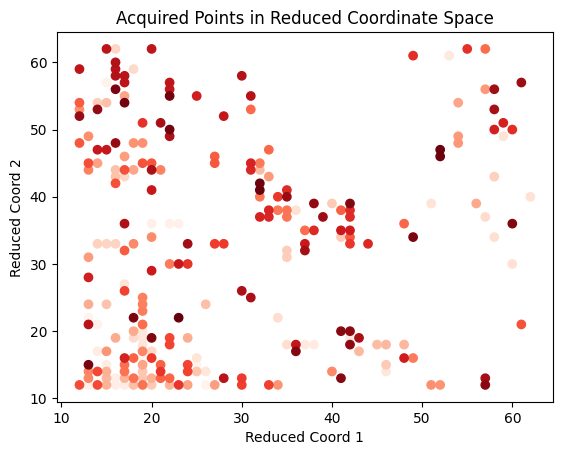

In [5]:
train_indices = output_dict.get("train_indices")

acquired_indices = [ind for ind in train_indices[-1] if ind not in train_indices[0]]

print(train_indices[-1].shape)
print(len(acquired_indices))

acquired_indices = np.array(acquired_indices)
print(acquired_indices)
acq_coords = output_dict["reduced_coords"][-1][acquired_indices]
# print(acq_coords.shape)
# print(acq_coords)
fig, ax = plt.subplots()
ax.scatter(acq_coords[:, 0], acq_coords[:, 1], c=np.arange(len(acq_coords)),  cmap = 'Reds', marker="o")
ax.set_xlabel("Reduced Coord 1")
ax.set_ylabel("Reduced Coord 2")
ax.set_title("Acquired Points in Reduced Coordinate Space")
plt.show()

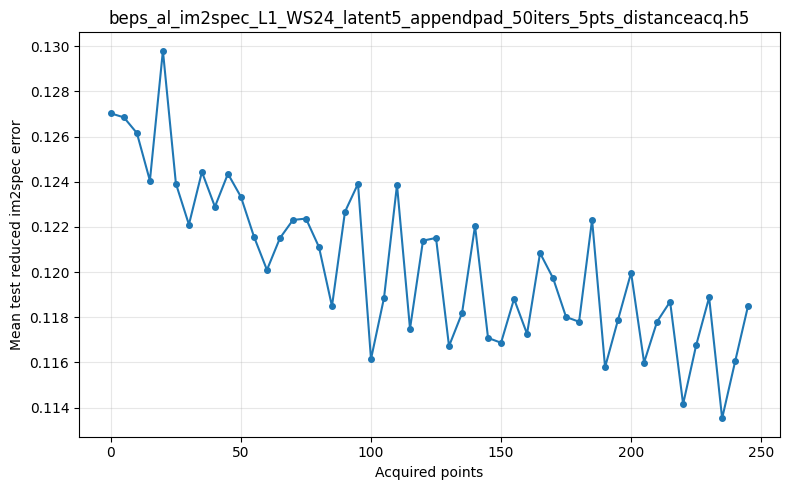

In [6]:
test_reduced_errors = calculate_test_reduced_errors(output_dict)
mean_test_reduced_errors = np.asarray([
    np.mean(errors) for errors in test_reduced_errors
])
points_per_iteration = infer_num_new_points(output_dict, output_file)
acquired_points = np.arange(len(mean_test_reduced_errors)) * points_per_iteration

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(acquired_points, mean_test_reduced_errors, marker="o", markersize=4)
ax.set_xlabel("Acquired points")
ax.set_ylabel("Mean test reduced im2spec error")
ax.set_title(output_file.name)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Plotting iteration -1 from beps_al_im2spec_L1_WS24_latent5_appendpad_50iters_5pts_distanceacq.h5


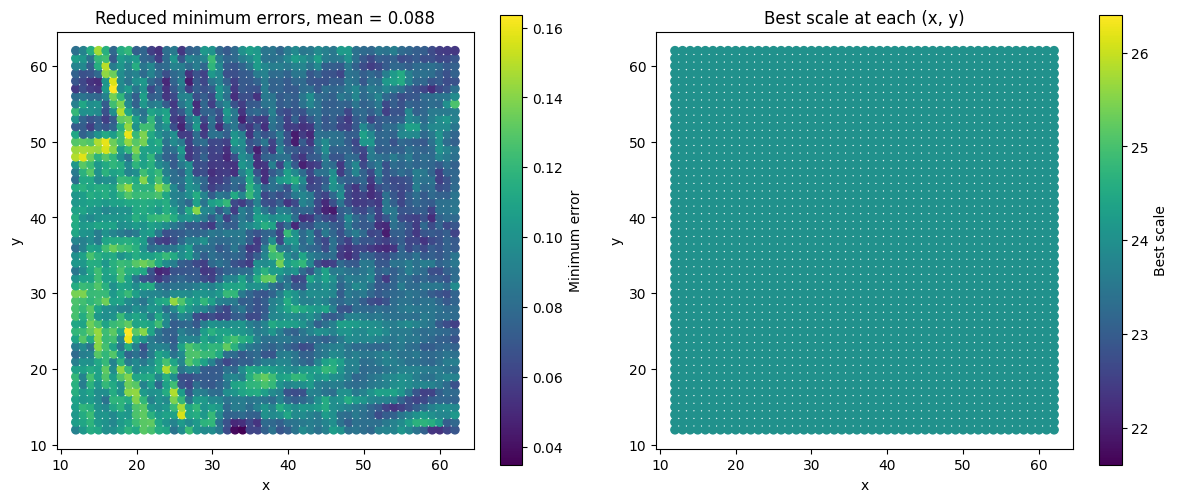

In [7]:
plot_iteration = -1
error_key = "reduced_errors"

if "reduced_coords" not in output_dict:
    raise KeyError(
        "This output file does not contain reduced_coords. "
        "Re-run pfm_ms_acqfn_script.py with reduced_coords saving enabled."
    )

print(f"Plotting iteration {plot_iteration} from {output_file.name}")
plot_reduced_errors_and_scales(
    output_dict[error_key][plot_iteration],
    output_dict["reduced_coords"][plot_iteration],
)

## Compare distance-based acquisition with random acquisition

FileNotFoundError: /home/cloud/nfs_share/vm_dir/NN_Error/notebooks/PFM/data/beps_active_learning_1d5um_eachSnorm_ss/beps_al_im2spec_attn_L1_WS24_latent5_appendpad_50iters_5pts_distanceacq.h5

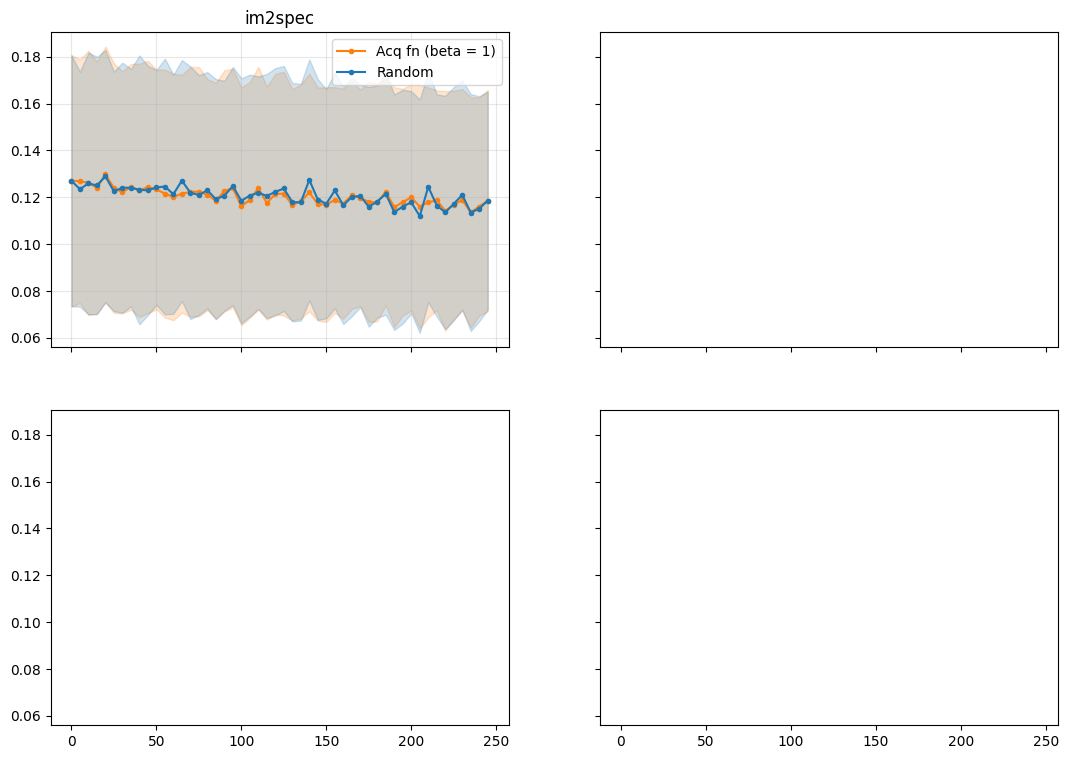

In [8]:
model_configs = {
    "im2spec": "appendpad",
    "im2spec_attn": "appendpad",
    "FNO": "appendinterpolate",
    "FNO_attn": "appendinterpolate",
}
comparison_results = {}
acquisition_colors = {"random": "tab:blue", "distance": "tab:orange"}
acquisition_labels = {
    "random": "Random",
    "distance": "Acq fn (beta = 1)",
}

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)

for ax, (model_type, append_mode) in zip(axes.flat, model_configs.items()):
    comparison_results[model_type] = {}

    for acquisition in ("distance", "random"):
        result_file = results_dir / (
            f"beps_al_{model_type}_{error_type}_WS{window_size}_latent{latent_dim}_"
            f"{append_mode}_{acquisition_iterations}iters_{num_new_points}pts_"
            f"{acquisition}acq.h5"
        )
        if not result_file.exists():
            raise FileNotFoundError(result_file)

        result_dict = load_h5_ragged(result_file)
        test_errors = calculate_test_reduced_errors(result_dict)
        mean_errors = np.asarray([np.mean(errors) for errors in test_errors])
        std_errors = np.asarray([np.std(errors) for errors in test_errors])
        points_per_iteration = infer_num_new_points(result_dict, result_file)
        acquired_points = np.arange(len(mean_errors)) * points_per_iteration

        comparison_results[model_type][acquisition] = {
            "output_file": result_file,
            "output_dict": result_dict,
            "mean_test_reduced_im2spec_error": mean_errors,
            "std_test_reduced_im2spec_error": std_errors,
        }

        mean_line = ax.plot(
            acquired_points, mean_errors, marker="o", markersize=3,
            color=acquisition_colors[acquisition],
            label=acquisition_labels[acquisition],
        )[0]
        ax.fill_between(
            acquired_points,
            mean_errors - std_errors,
            mean_errors + std_errors,
            color=mean_line.get_color(),
            alpha=0.2,
        )

    ax.set_title(model_type)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.supxlabel("Acquired points")
fig.supylabel("Test reduced im2spec error (mean ± std)")
fig.suptitle(f"PFM Acq fn (beta = 1) vs random acquisition ({error_type})")
fig.tight_layout()
plt.show()

/tmp/ipykernel_1658852/3315824955.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


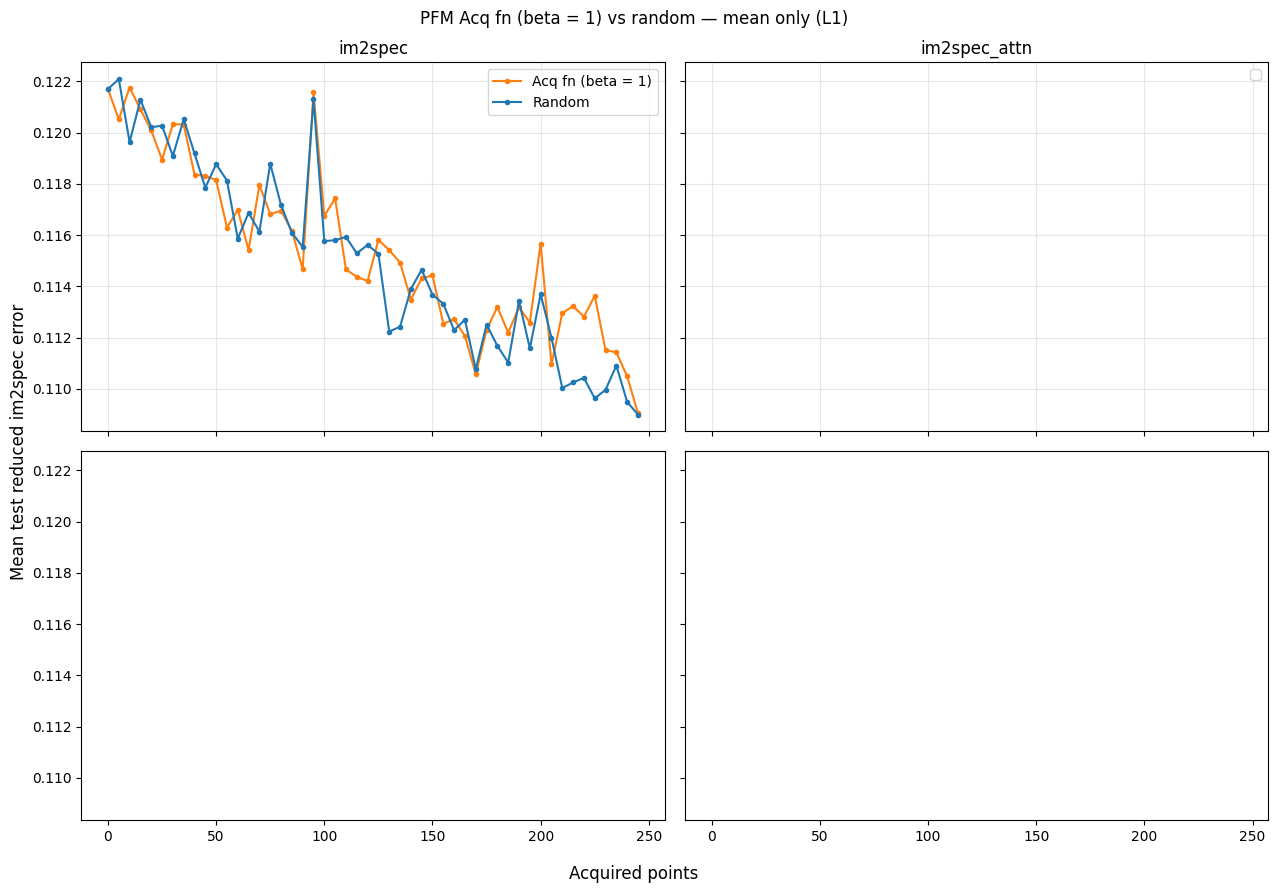

In [ ]:
# Plot only the mean test error curves (without the standard-deviation bands).
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)

for ax, (model_type, acquisition_results) in zip(
    axes.flat, comparison_results.items()
):
    for acquisition, result in acquisition_results.items():
        mean_errors = result["mean_test_reduced_im2spec_error"]
        points_per_iteration = infer_num_new_points(
            result["output_dict"], result["output_file"]
        )
        acquired_points = np.arange(len(mean_errors)) * points_per_iteration

        ax.plot(
            acquired_points,
            mean_errors,
            marker="o",
            markersize=3,
            color=acquisition_colors[acquisition],
            label=acquisition_labels[acquisition],
        )

    ax.set_title(model_type)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.supxlabel("Acquired points")
fig.supylabel("Mean test reduced im2spec error")
fig.suptitle(f"PFM Acq fn (beta = 1) vs random — mean only ({error_type})")
fig.tight_layout()
plt.show()

In [ ]:
def rolling_average(array, window=5):
    p_average = []

    array = np.array(array).squeeze()
    for i in range(len(array)):
        if i + 1 < window:
            k = i + 1
        else:
            k = window

        total = 0
        for j in range(k):
            total += array[i - j]

        p_average.append(total / k)

    return np.array(p_average).squeeze()

/tmp/ipykernel_1658852/3569456530.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


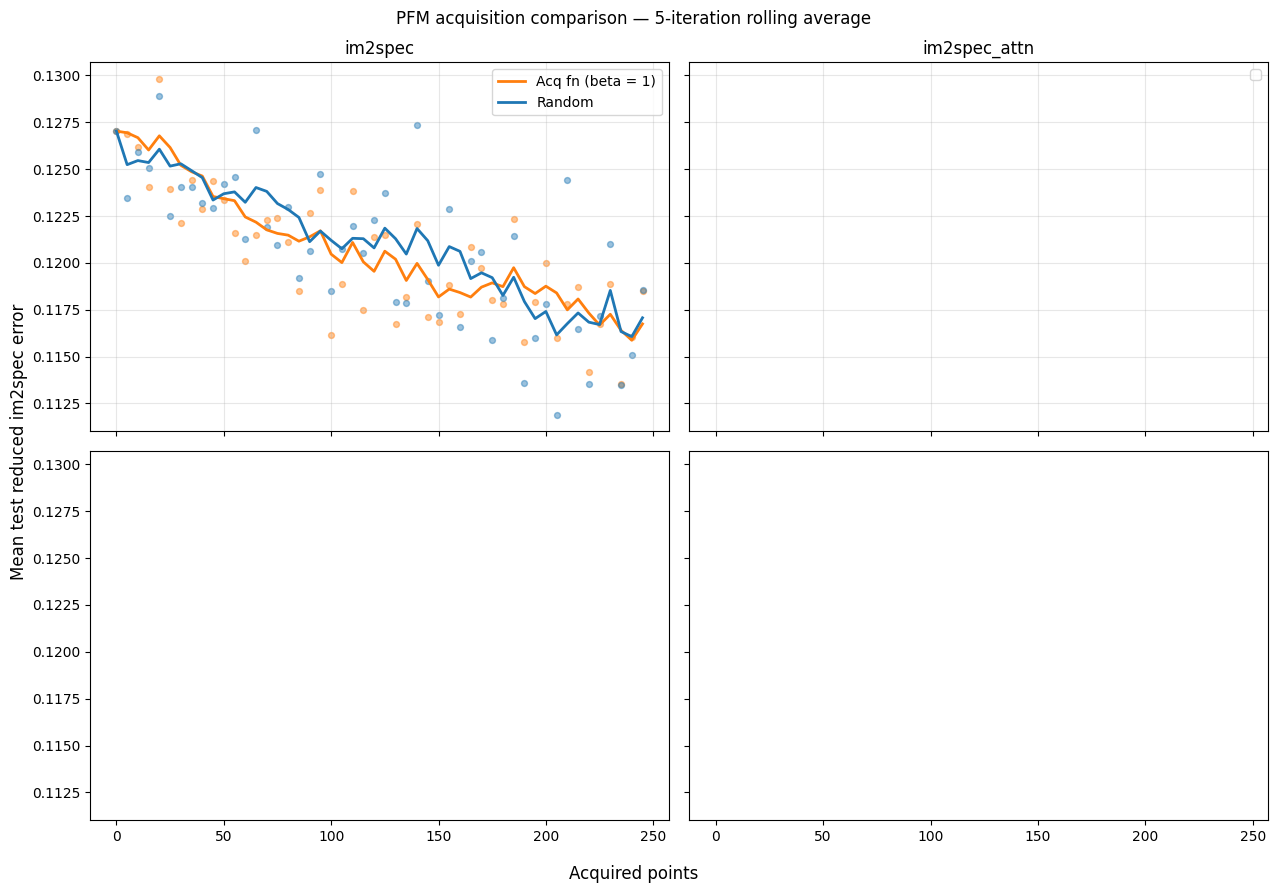

In [ ]:
# Raw mean errors as scatter points and their rolling averages as solid lines.
rolling_window = 5

if rolling_window < 1:
    raise ValueError("rolling_window must be at least 1")

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)

for ax, (model_type, acquisition_results) in zip(
    axes.flat, comparison_results.items()
):
    for acquisition, result in acquisition_results.items():
        mean_errors = np.asarray(result["mean_test_reduced_im2spec_error"])
        points_per_iteration = infer_num_new_points(
            result["output_dict"], result["output_file"]
        )
        acquired_points = np.arange(len(mean_errors)) * points_per_iteration
        rolling_mean = rolling_average(mean_errors, window=rolling_window)
        color = acquisition_colors[acquisition]

        ax.scatter(
            acquired_points,
            mean_errors,
            color=color,
            s=18,
            alpha=0.45,
        )
        ax.plot(
            acquired_points,
            rolling_mean,
            color=color,
            linewidth=2,
            label=acquisition_labels[acquisition],
        )

    ax.set_title(model_type)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.supxlabel("Acquired points")
fig.supylabel("Mean test reduced im2spec error")
fig.suptitle(
    f"PFM acquisition comparison — {rolling_window}-iteration rolling average"
)
fig.tight_layout()
plt.show()